In [1]:
import numpy as np
import pandas as pd
import sklearn as sk
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns

import os
import glob
from contextlib import contextmanager
import joblib as job

In [2]:
if "get_ipython" not in globals() or "get_ipython" in globals() and get_ipython().__class__.__name__ == "TerminalInteractiveShell":
    matplotlib.use("Agg")
    plt.rcParams.update({"figure.dpi": 200})

def plot(figsize=(6.4, 4.8), **kwargs):
    plt.gcf().set_size_inches(*figsize)
    if "get_ipython" not in globals() or get_ipython().__class__.__name__ == "TerminalInteractiveShell":
        plt.savefig("a.png", **kwargs)
        plt.clf()
        plt.cla()
    else:
        plt.show()
    plt.close()

def dbg(x):
    print(x)
    return x

# https://stackoverflow.com/a/17511341
def ceildiv(a, b):
    return -(a // -b)

def nplots(n, cols, tight=None, figsize=None):
    rows = ceildiv(n, cols)
    figsize=figsize if figsize is not None else (6 * cols, 4 * rows)

    fig, axes = plt.subplots(rows, cols, figsize=figsize)

    for i, ax in enumerate(axes.flatten() if n != 1 else [axes]):
        if i >= n:
            fig.delaxes(ax)
            continue

        yield i, ax

    if tight != False and (n != 1 or tight == True):
        plt.tight_layout()

    plot(figsize=figsize)

@contextmanager
def oneplot(tight=None, figsize=None):
    for _, ax in nplots(1, 1, tight=tight, figsize=figsize):
        yield ax

sample_prev_df=None
sample_prev_n=None
sample_ret=None

def sample(df, n=400_000):
    global sample_prev_df
    global sample_prev_n
    global sample_ret

    if sample_prev_df is df and n == sample_prev_n:
        return sample_ret

    sample_ret = None
    sample_prev_df = df
    sample_prev_n = n

    return (sample_ret := df.sample(n, random_state=217, replace=False))

In [3]:
def load_clean(pat):
    return pd.concat([
        pd.read_csv(
            dbg(name),
            dtype=dict(
                VendorID=int,
                passenger_count=float,
                trip_distance=float,
                RatecodeID="category",
                # has NAs, but we're unlikely to use this column so
                # don't drop it
                store_and_fwd_flag="boolean",
                PULocationID="category",
                DOLocationID="category",
                payment_type=int,
                fare_amount=float,
                extra=float,
                mta_tax=float,
                tip_amount=float,
                tolls_amount=float,
                improvement_surcharge=float,
                total_amount=float,
                congestion_surcharge=float,
                Airport_fee=float,
                duration_hours=float,
                avg_speed_mph=float,
                fare_per_hour=float,
            ),
            parse_dates=[
                "tpep_pickup_datetime",
                "tpep_dropoff_datetime",
            ],
        )
        for name in sorted(glob.glob(f"../dataset-clean/{pat}"))
    ], ignore_index=True)

In [4]:
rides_train = load_clean("train_*")
rides_test = load_clean("test_*")
# rides_sample = load_clean("sample_*")

../dataset-clean/train_00.csv
../dataset-clean/train_01.csv
../dataset-clean/train_02.csv
../dataset-clean/train_03.csv
../dataset-clean/train_04.csv
../dataset-clean/train_05.csv
../dataset-clean/train_06.csv
../dataset-clean/train_07.csv
../dataset-clean/train_08.csv
../dataset-clean/train_09.csv
../dataset-clean/train_10.csv
../dataset-clean/train_11.csv
../dataset-clean/train_12.csv
../dataset-clean/train_13.csv
../dataset-clean/train_14.csv
../dataset-clean/test_00.csv
../dataset-clean/test_01.csv
../dataset-clean/test_02.csv
../dataset-clean/test_03.csv
../dataset-clean/test_04.csv


In [5]:
def group_zone_hour(
    df,
    aggs,
):
    """
    Aggregrate trips into zone-hour statistics

    df : pd.DataFrame
        Trip-level dataframe
    aggs : function, str, list, dict or None
        Argument to pd.DataFrameGroupBy.agg, specify which columsn and
        how aggregation should be done

    Returns:
    pd.DataFrame
        Dataframe with zone-hour and aggregated values
    """
    378798
    586920

    df = (
        df
            .groupby(["PULocationID", "pickup_hour"], observed=True)
            .agg(aggs)
            .reset_index()
    )
    # flaten column names
    df.columns = [(f"cur_{x}_{y}" if y else x) for (x, y) in df.columns]

    return df

def with_lags(
    df,
    feature,
    agg,
    window="2h",
    offsets=["1h"],
):
    agged = df.rename(
        columns=lambda x: x.removeprefix("cur_") if isinstance(x, str) else x,
    ).groupby("PULocationID", observed=True)[["pickup_hour", feature]].rolling(
        window,
        on="pickup_hour",
    ).agg(agg)

    for offset in offsets:
        df = pd.merge(
            df,
            agged.assign(
                pickup_hour=agged["pickup_hour"] +
                    (offset if not isinstance(offset, str) else pd.Timedelta(offset)),
            ).rename(
                columns=lambda x:
                    f"lag_{feature}-{agg}-{window}-{offset}" if x not in ["PULocationID", "pickup_hour"] else x,
            ),
            how="left",
            on=["PULocationID", "pickup_hour"],
        )

    return df

In [6]:
demand_lags = [
    ("count", "mean", "1h", ["23h", "24h", "48h"]),
    ("count", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_sum", "mean", "1h", ["23h", "24h", "48h"]),
    ("duration_hours_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_sum", "mean", "1h", ["23h", "24h", "48h"]),
    ("trip_distance_sum", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("avg_speed_mph_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("ratecode_is_1_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_2_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_3_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_4_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_5_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_6_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_99_mean", "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_1_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_2_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_3_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_4_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_5_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_6_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_99_mean", "mean", "1d", ["1d", "2d"]),

    ("do_is_upper_east_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_midtown_mean"   , "mean", "2h", ["23h", "24h"]),
    ("do_is_financial_mean" , "mean", "2h", ["23h", "24h"]),
    ("do_is_turtle_bay_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_north_mean"     , "mean", "2h", ["23h", "24h"]),
    ("do_is_upper_east_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_midtown_mean"   , "mean", "1d", ["1d", "2d"]),
    ("do_is_financial_mean" , "mean", "1d", ["1d", "2d"]),
    ("do_is_turtle_bay_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_north_mean"     , "mean", "1d", ["1d", "2d"]),
]

revenue_lags = [
    ("fare_amount_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("fare_amount_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("duration_hours_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("duration_hours_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("trip_distance_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("trip_distance_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("avg_speed_mph_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("avg_speed_mph_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("tip_ratio_mean", "mean", "1h", ["23h", "24h", "48h"]),
    ("tip_ratio_mean", "mean", "1d", ["1d", "2d", "5d", "7d"]),

    ("ratecode_is_1_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_2_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_3_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_4_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_5_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_6_mean" , "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_99_mean", "mean", "2h", ["23h", "24h"]),
    ("ratecode_is_1_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_2_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_3_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_4_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_5_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_6_mean" , "mean", "1d", ["1d", "2d"]),
    ("ratecode_is_99_mean", "mean", "1d", ["1d", "2d"]),

    ("do_is_upper_east_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_midtown_mean"   , "mean", "2h", ["23h", "24h"]),
    ("do_is_financial_mean" , "mean", "2h", ["23h", "24h"]),
    ("do_is_turtle_bay_mean", "mean", "2h", ["23h", "24h"]),
    ("do_is_north_mean"     , "mean", "2h", ["23h", "24h"]),
    ("do_is_upper_east_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_midtown_mean"   , "mean", "1d", ["1d", "2d"]),
    ("do_is_financial_mean" , "mean", "1d", ["1d", "2d"]),
    ("do_is_turtle_bay_mean", "mean", "1d", ["1d", "2d"]),
    ("do_is_north_mean"     , "mean", "1d", ["1d", "2d"]),
]

In [7]:
numerical_pipeline = sk.pipeline.Pipeline([
    ("imputer", sk.impute.SimpleImputer(strategy="mean")),
    ("scaler", sk.preprocessing.QuantileTransformer()),
])

full_pipeline = sk.compose.ColumnTransformer([
    (
        "num",
        numerical_pipeline,
        sk.compose.make_column_selector(dtype_include=np.float64),
    ),
    (
        "cat_ohe",
        sk.preprocessing.OneHotEncoder(
            categories=[
                list(rides_train["PULocationID"].unique()),
                list(range(24)),
            ]
        ),
        ["PULocationID", "pickup_hour_of_day"],
    ),
], remainder="drop")

In [8]:
zone_upper_east = [str(x) for x in [236, 237, 141, 142, 262]]
zone_midtown = [str(x) for x in [161, 162, 163]]
zone_financial = [str(x) for x in [12, 88, 87, 261]]
zone_turtle_bay = [str(x) for x in [162, 229]]
zone_north = [str(x) for x in [42, 116, 127, 243, 255]]

def build_xy(rides_clean, y_col, lags):
    rides_feat = rides_clean.assign(
        pickup_hour = lambda x: x["tpep_pickup_datetime"].dt.floor("1h"),
        pickup_hour_of_day = lambda x:
            x["tpep_pickup_datetime"].dt.hour +
            (x["tpep_pickup_datetime"].dt.minute / 60),
        # monday = 0
        pickup_day_of_week = lambda x:
            (x["tpep_pickup_datetime"].dt.day_of_week) +
            (x["tpep_pickup_datetime"].dt.hour / 24) +
            (x["tpep_pickup_datetime"].dt.minute / (60 * 24)),
        ratecode_is_airport = lambda x: x["RatecodeID"].isin(["2", "3"]),
        # total amount includes extra surcharges/fees => stronger patterns tip %
        tip_ratio = lambda x: (x["tip_amount"] / (x["total_amount"] - x["tip_amount"])).fillna(0),
    )

    rides_hour = group_zone_hour(
        pd.concat(
            [
                rides_feat,
                pd.DataFrame({
                    f"ratecode_is_{n}": rides_feat["RatecodeID"] == n
                    for n in [1, 2, 3, 4, 5, 6, 99]
                }),
                pd.DataFrame(dict(
                    do_is_upper_east=rides_feat["DOLocationID"].isin(zone_upper_east),
                    do_is_midtown=rides_feat["DOLocationID"].isin(zone_midtown),
                    do_is_financial=rides_feat["DOLocationID"].isin(zone_financial),
                    do_is_turtle_bay=rides_feat["DOLocationID"].isin(zone_turtle_bay),
                    do_is_north=rides_feat["DOLocationID"].isin(zone_north),
                ))
            ],
            axis=1,
        ),
        dict(
            passenger_count="mean",
            trip_distance=["sum", "mean"],
            # amount without tips or fees
            fare_amount=["sum", "mean"],
            # the following are somewhat fixed fees so the means
            # are losely counts of rides where the fee is charged
            # not much info intrinsically but maybe a patern?
            mta_tax="mean",
            tolls_amount="mean",
            improvement_surcharge="mean",
            congestion_surcharge="mean",
            Airport_fee="mean",
            # total amount including tips and fees
            # * in our case these are "noise" when making predictions
            # * if we really wanted to be vultures we might look at tips
            #   as an indicator of routes where we could charge more
            total_amount=["sum", "mean"],
            tip_amount="mean",
            tip_ratio="mean",
            # probably correlated with demand
            # * count used in this column arbitrarily
            duration_hours=["count", "sum", "mean"],
            avg_speed_mph="mean",
            fare_per_hour="mean",
            ratecode_is_airport=["mean", "count"],

            ratecode_is_1="mean",
            ratecode_is_2="mean",
            ratecode_is_3="mean",
            ratecode_is_4="mean",
            ratecode_is_5="mean",
            ratecode_is_6="mean",
            ratecode_is_99="mean",

            do_is_upper_east="mean",
            do_is_midtown="mean",
            do_is_financial="mean",
            do_is_turtle_bay="mean",
            do_is_north="mean",
        ),
    ).assign(
        pickup_hour_of_day=lambda x: x["pickup_hour"].dt.hour,
    ).rename(
        columns=dict(
            cur_duration_hours_count="cur_count",
        )
    )

    X = rides_hour

    for feat, agg, window, offsets in lags:
        X = with_lags(
            X,
            feat,
            agg,
            window=window,
            offsets=offsets,
        )

    index_cols = [
        "PULocationID",
        "pickup_hour",
        "pickup_hour_of_day",
    ]

    y = X[y_col]
    X = X.drop(columns=[
        x
        for x in X.columns
        if x.startswith("cur_")
    ])

    assert all((x.startswith("lag_") or x in index_cols) for x in X.columns)

    return X, y

In [9]:
def evalcv(
    rides_clean_train,
    rides_clean_test,
    target,
    lags,
    model,
    param_grid,
):
    pre = sk.clone(full_pipeline)

    print("building sets")

    X, y = build_xy(rides_clean_train, target, lags)
    X = pre.fit_transform(X, y)
    X = X.toarray() if hasattr(X, "toarray") else X
    
    X_test, y_test = build_xy(rides_clean_test, target, lags)
    X_test = pre.transform(X_test)
    X_test = X_test.toarray() if hasattr(X, "toarray") else X_test

    print("train set size", X.shape)
    print("test set size", X_test.shape)
    print("starting gridsearch")

    cv = sk.model_selection.GridSearchCV(
        model,
        param_grid=param_grid,
        cv=sk.model_selection.ShuffleSplit(
            n_splits=2,
            train_size=200_000,
            test_size=50_000,
        ),
        scoring="neg_mean_squared_error",
        n_jobs=-1,
        verbose=10,
        error_score="raise",
    )

    cv.fit(X, y)

    print("finished gridsearch")

    print("\n" * 5)

    print("=")
    print("==")
    print("===")
    print("==== fit complete ====")
    print("===")
    print("==")
    print("=")

    print(cv.best_params_)
    best = model.set_params(**cv.best_params_)
    best.fit(X, y)

    y_pred = best.predict(X_test)

    imp = sk.inspection.permutation_importance(
        best,
        X_test,
        y_test,
        scoring="neg_mean_squared_error",
        n_repeats=5,
        random_state=2718,
        n_jobs=-1,
    )

    feature_names = pre.get_feature_names_out()

    imp_df = pd.DataFrame({
        "feature": feature_names,
        "importance_mean": imp.importances_mean,
        "importance_std": imp.importances_std,
    }).sort_values("importance_mean", ascending=True).reset_index(drop=True)

    print("importance complete")

    return cv, y_test, y_pred, imp_df

In [10]:
nn_param_grid = {
    "hidden_layer_sizes": [
        (25, 25, 10, 15),
        (25, 25, 25),
        (50, 25),
    ],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.001, 0.01],
}

cv_demand, y_test, y_pred, imp = evalcv(
    rides_train,
    rides_test,
    "cur_count",
    demand_lags,
    sk.neural_network.MLPRegressor(random_state=2718),
    nn_param_grid,
)

building sets
train set size (388101, 174)
test set size (116185, 174)
starting gridsearch
Fitting 2 folds for each of 36 candidates, totalling 72 fits
[CV 2/2; 2/36] START activation=relu, alpha=0.0001, hidden_layer_sizes=(25, 25, 10, 15), learning_rate_init=0.01
[CV 1/2; 1/36] START activation=relu, alpha=0.0001, hidden_layer_sizes=(25, 25, 10, 15), learning_rate_init=0.001
[CV 2/2; 1/36] START activation=relu, alpha=0.0001, hidden_layer_sizes=(25, 25, 10, 15), learning_rate_init=0.001
[CV 2/2; 4/36] START activation=relu, alpha=0.0001, hidden_layer_sizes=(25, 25, 25), learning_rate_init=0.01
[CV 1/2; 5/36] START activation=relu, alpha=0.0001, hidden_layer_sizes=(50, 25), learning_rate_init=0.001
[CV 1/2; 4/36] START activation=relu, alpha=0.0001, hidden_layer_sizes=(25, 25, 25), learning_rate_init=0.01
[CV 1/2; 3/36] START activation=relu, alpha=0.0001, hidden_layer_sizes=(25, 25, 25), learning_rate_init=0.001
[CV 1/2; 2/36] START activation=relu, alpha=0.0001, hidden_layer_sizes=(2

/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV 2/2; 5/36] END activation=relu, alpha=0.0001, hidden_layer_sizes=(50, 25), learning_rate_init=0.001;, score=-723.740 total time= 1.5min
[CV 2/2; 7/36] START activation=relu, alpha=0.001, hidden_layer_sizes=(25, 25, 10, 15), learning_rate_init=0.001


/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV 1/2; 1/36] END activation=relu, alpha=0.0001, hidden_layer_sizes=(25, 25, 10, 15), learning_rate_init=0.001;, score=-707.872 total time= 1.7min
[CV 1/2; 8/36] START activation=relu, alpha=0.001, hidden_layer_sizes=(25, 25, 10, 15), learning_rate_init=0.01


...

[CV 2/2; 33/36] END activation=tanh, alpha=0.01, hidden_layer_sizes=(25, 25, 25), learning_rate_init=0.001;, score=-660.191 total time= 1.6min


/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV 1/2; 35/36] END activation=tanh, alpha=0.01, hidden_layer_sizes=(50, 25), learning_rate_init=0.001;, score=-708.443 total time= 1.3min


/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


[CV 2/2; 35/36] END activation=tanh, alpha=0.01, hidden_layer_sizes=(50, 25), learning_rate_init=0.001;, score=-666.886 total time= 1.4min
finished gridsearch






=
==
===
==== fit complete ====
===
==
=
{'activation': 'tanh', 'alpha': 0.0001, 'hidden_layer_sizes': (25, 25, 10, 15), 'learning_rate_init': 0.001}
importance complete


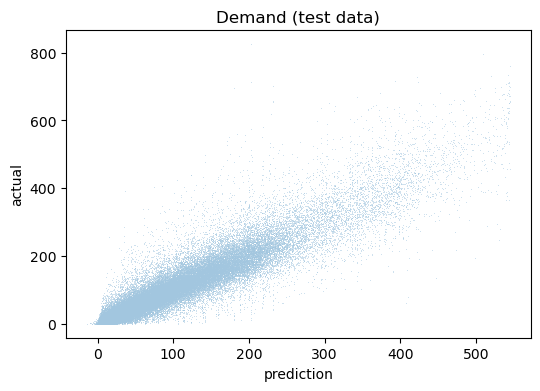

In [11]:
with oneplot() as ax:
    sns.scatterplot(
        ax=ax,
        x=y_pred,
        y=y_test,
        s=0.2,
        linewidth=0,
    ),
    ax.set_xlabel("prediction")
    ax.set_ylabel("actual")
    ax.set_title("Demand (test data)")

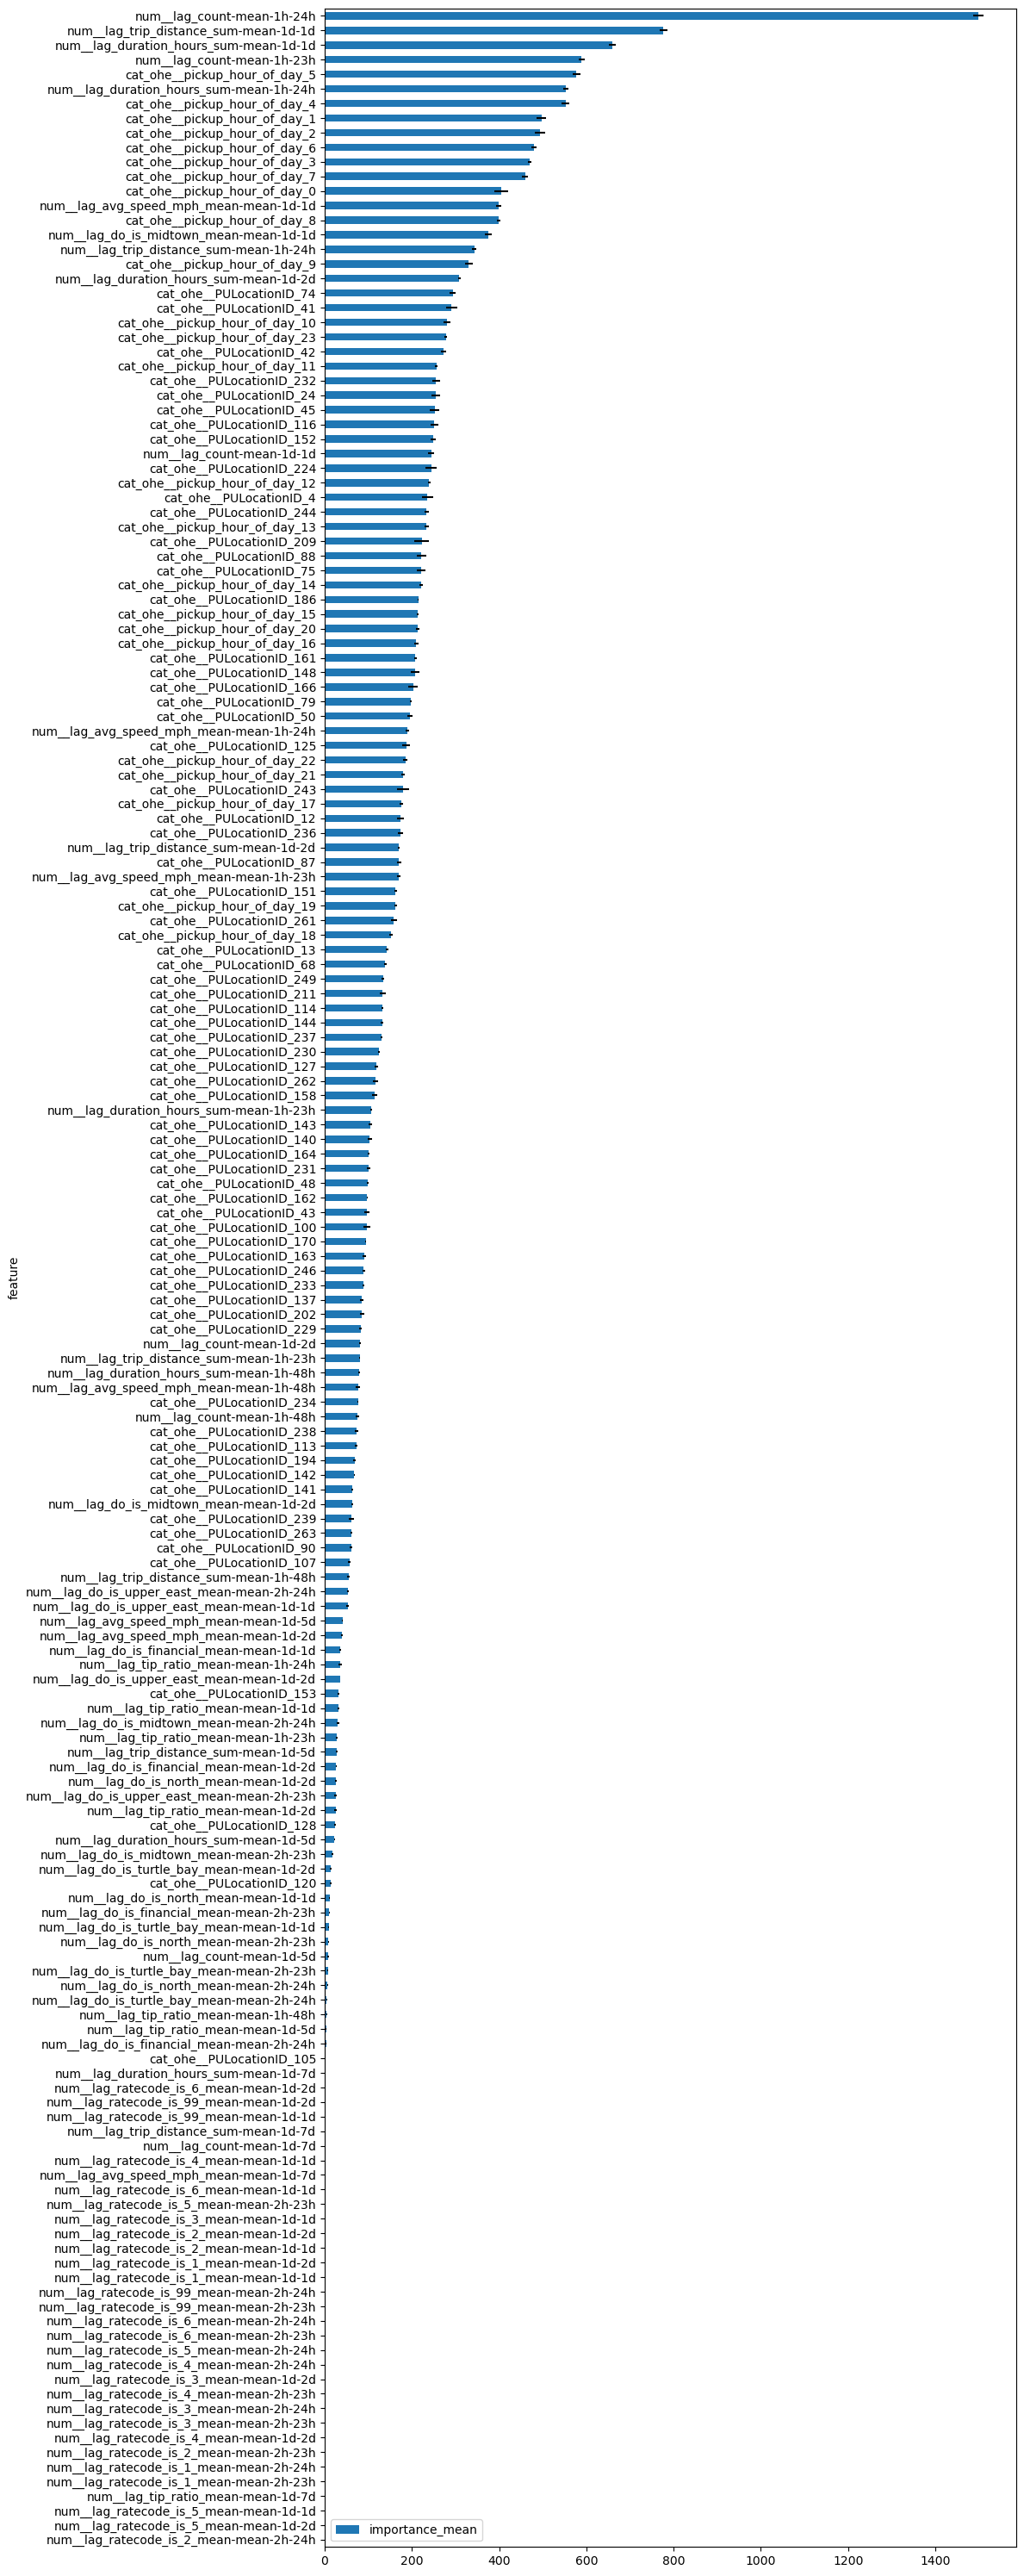

In [12]:
with oneplot(figsize=(12, 30), tight=True) as ax:
    imp.plot.barh(
        ax=ax,
        x="feature",
        y="importance_mean",
        xerr="importance_std",
    )

In [13]:
gb_param_grid = {
    "min_samples_leaf": [10, 20, 40],
    "max_depth": [None, 64],
    "max_leaf_nodes": [31, 63, None],
    "learning_rate": [0.01, 0.1, 0.12],
}

cv_demand, y_test, y_pred, imp = evalcv(
    rides_train,
    rides_test,
    "cur_fare_amount_mean",
    revenue_lags,
    sk.ensemble.HistGradientBoostingRegressor(random_state=2718, max_iter=10),
    gb_param_grid,
)


building sets
train set size (388101, 174)
test set size (116185, 174)
starting gridsearch
Fitting 2 folds for each of 54 candidates, totalling 108 fits
[CV 1/2; 1/54] START learning_rate=0.01, max_depth=None, max_leaf_nodes=31, min_samples_leaf=10
[CV 2/2; 1/54] START learning_rate=0.01, max_depth=None, max_leaf_nodes=31, min_samples_leaf=10
[CV 2/2; 2/54] START learning_rate=0.01, max_depth=None, max_leaf_nodes=31, min_samples_leaf=20
[CV 1/2; 2/54] START learning_rate=0.01, max_depth=None, max_leaf_nodes=31, min_samples_leaf=20
[CV 1/2; 3/54] START learning_rate=0.01, max_depth=None, max_leaf_nodes=31, min_samples_leaf=40
[CV 1/2; 4/54] START learning_rate=0.01, max_depth=None, max_leaf_nodes=63, min_samples_leaf=10
[CV 2/2; 3/54] START learning_rate=0.01, max_depth=None, max_leaf_nodes=31, min_samples_leaf=40
[CV 1/2; 5/54] START learning_rate=0.01, max_depth=None, max_leaf_nodes=63, min_samples_leaf=20
[CV 2/2; 5/54] START learning_rate=0.01, max_depth=None, max_leaf_nodes=63, min

/nix/store/p9ny36zcy47qrh4wyr0prwx0i04w2sv3-python3-3.13.12-env/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[CV 1/2; 7/54] END learning_rate=0.01, max_depth=None, max_leaf_nodes=None, min_samples_leaf=10;, score=-46.402 total time= 1.0min
[CV 1/2; 22/54] END learning_rate=0.1, max_depth=None, max_leaf_nodes=63, min_samples_leaf=10;, score=-36.535 total time=   7.4s
[CV 2/2; 25/54] START learning_rate=0.1, max_depth=None, max_leaf_nodes=None, min_samples_leaf=10
[CV 2/2; 22/54] END learning_rate=0.1, max_depth=None, max_leaf_nodes=63, min_samples_leaf=10;, score=-36.275 total time=   7.2s
[CV 2/2; 26/54] START learning_rate=0.1, max_depth=None, max_leaf_nodes=None, min_samples_leaf=20
[CV 1/2; 25/54] START learning_rate=0.1, max_depth=None, max_leaf_nodes=None, min_samples_leaf=10
[CV 1/2; 23/54] END learning_rate=0.1, max_depth=None, max_leaf_nodes=63, min_samples_leaf=20;, score=-36.510 total time=   7.2s
[CV 1/2; 27/54] START learning_rate=0.1, max_depth=None, max_leaf_nodes=None, min_samples_leaf=40
[CV 2/2; 23/54] END learning_rate=0.1, max_depth=None, max_leaf_nodes=63, min_samples_leaf

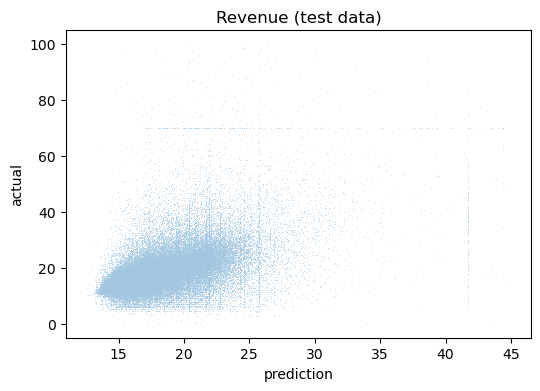

In [14]:
with oneplot() as ax:
    sns.scatterplot(
        ax=ax,
        x=y_pred,
        y=y_test,
        s=0.2,
        linewidth=0,
    ),
    ax.set_xlabel("prediction")
    ax.set_ylabel("actual")
    ax.set_title("Revenue (test data)")

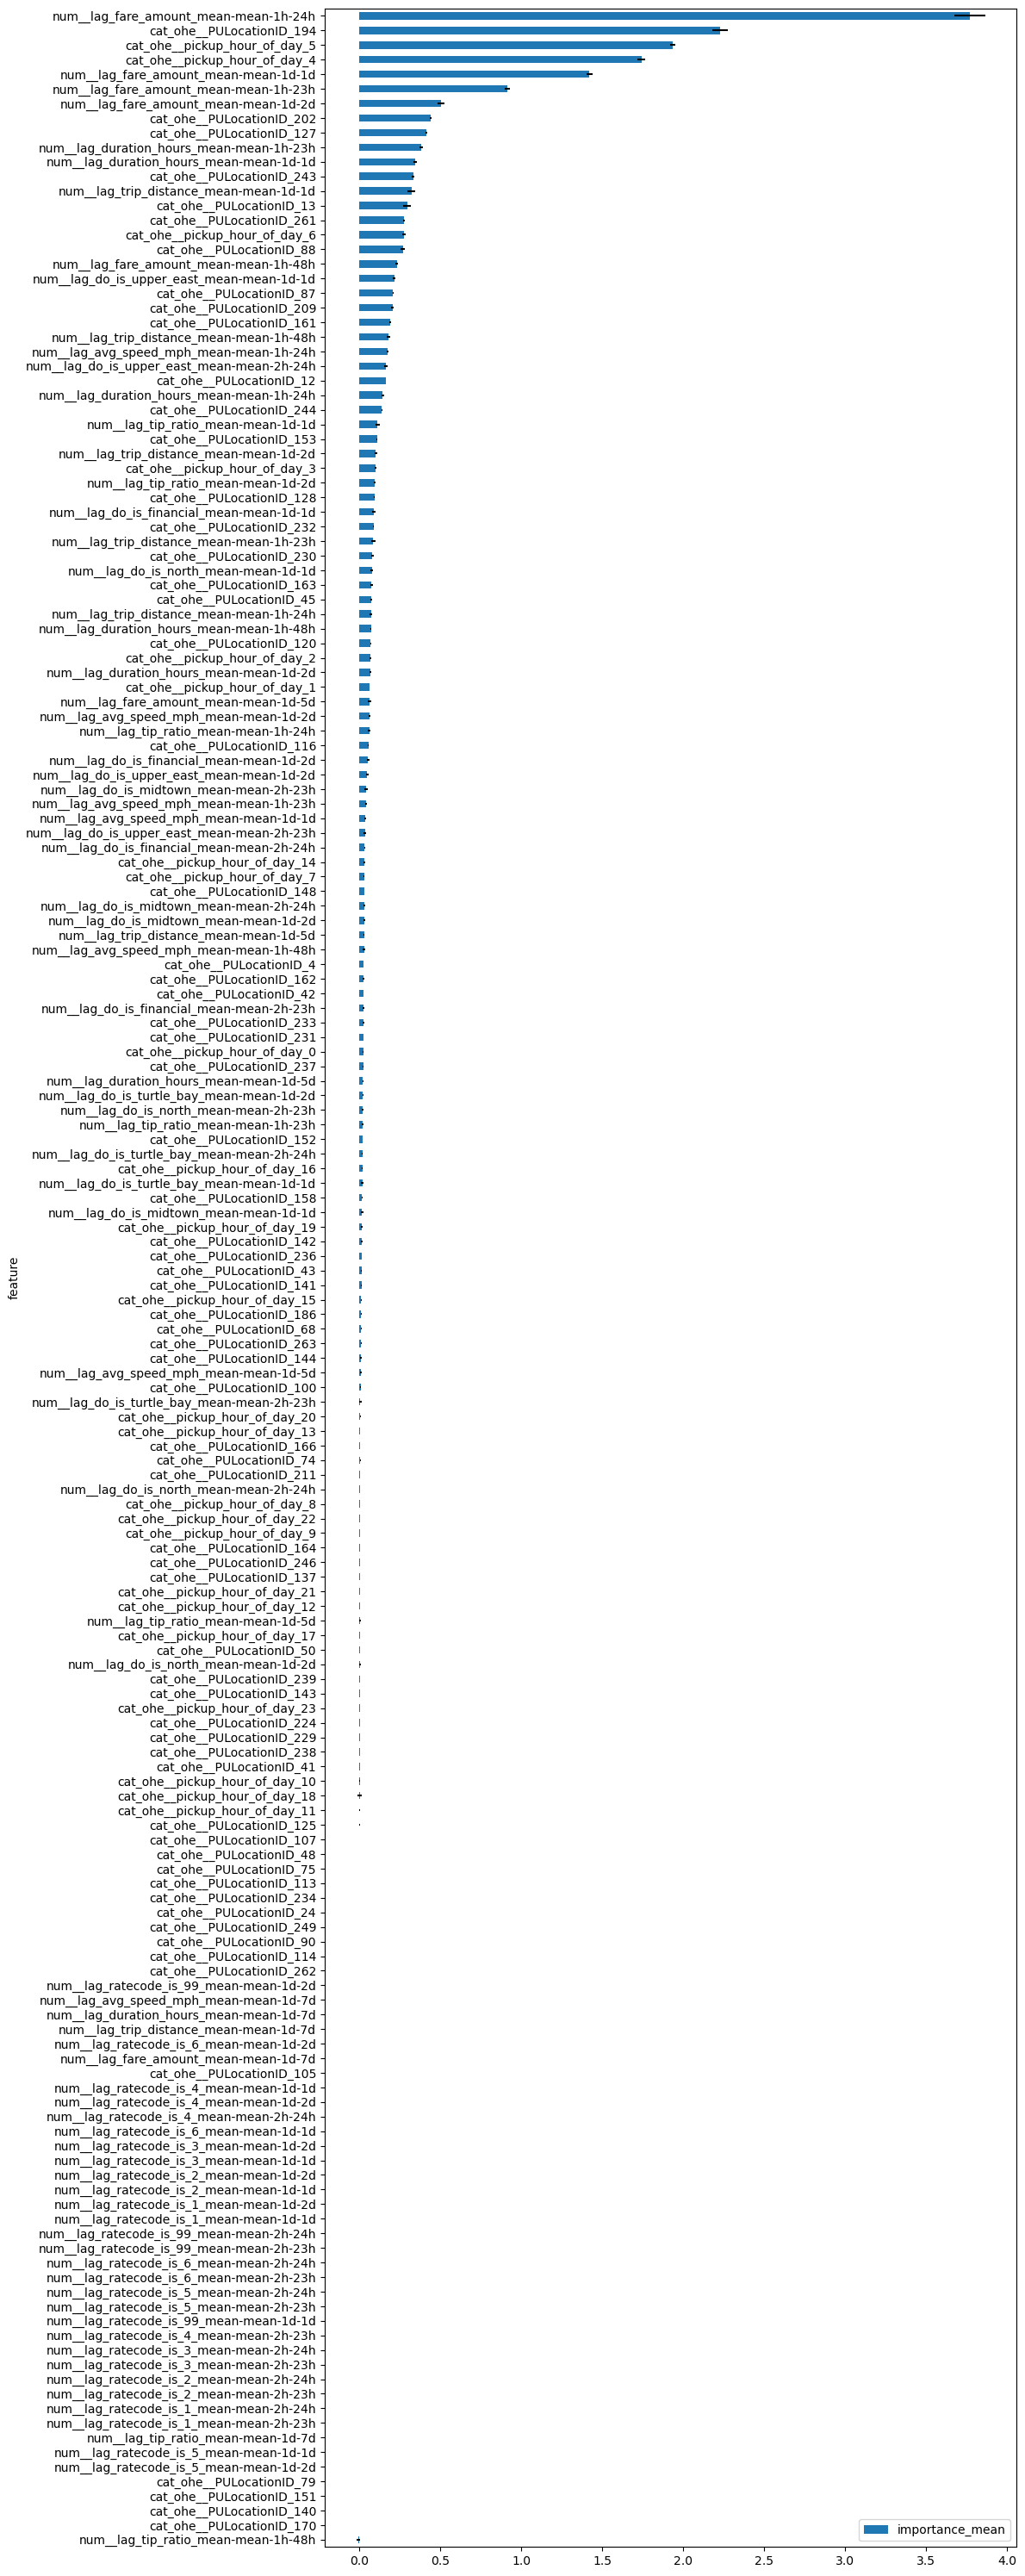

In [15]:
with oneplot(figsize=(12, 30), tight=True) as ax:
    imp.plot.barh(
        ax=ax,
        x="feature",
        y="importance_mean",
        xerr="importance_std",
    )